# Mini-Project 1: Fetching and Displaying a Weather Forecast
**Course:** Python Assignment 2, Advent 2026  
**Description:** This notebook fetches geocoding and weather forecast data using Open-Meteo APIs via custom robust HTTP requests, processes the data using Pandas, visualizes the forecast with Matplotlib, and provides a comprehensive report.

In [1]:
# --- CONFIGURATION CELL ---
LOCATION_NAME = "Namugongo"
CONTACT_EMAIL = "40081@student.ucu.ac.ug"  
import sys
import os
# Add parent directory to system path so we can import from src/
current_dir = os.getcwd()
parent_dir = os.path.abspath(os.path.join(current_dir, '..'))
if parent_dir not in sys.path:
    sys.path.append(parent_dir)

print(f"Configuration loaded for: {LOCATION_NAME}")
print(f"Contact Email: {CONTACT_EMAIL}")

Configuration loaded for: Namugongo
Contact Email: 40081@student.ucu.ac.ug


## Part A: HTTP Fundamentals
Here we compare using Python's built-in `urllib` versus the external `requests` library for geocoding a location. We also inspect status codes, headers, and response times.

In [2]:
import urllib.request
import urllib.parse
import json
import time
import requests

# 1. Using urllib
url_base = "https://geocoding-api.open-meteo.com/v1/search"
query_params = {"name": LOCATION_NAME, "count": 5}
encoded_query = urllib.parse.urlencode(query_params)
full_url = f"{url_base}?{encoded_query}"

headers = {"User-Agent": f"StudentProject ({CONTACT_EMAIL})"}

start_time = time.time()
req = urllib.request.Request(full_url, headers=headers)
try:
    with urllib.request.urlopen(req) as response:
        urllib_time = time.time() - start_time
        urllib_status = response.status
        urllib_content_type = response.headers.get("Content-Type")
        urllib_data = json.loads(response.read().decode())
except Exception as e:
    print(f"urllib error: {e}")

# 2. Using requests
start_time = time.time()
req_response = requests.get(url_base, params=query_params, headers=headers, timeout=5.0)
requests_time = time.time() - start_time

print(f"--- Comparison Results for '{LOCATION_NAME}' ---")
print(f"urllib  -> Status: {urllib_status}, Content-Type: {urllib_content_type}, Time: {urllib_time:.4f}s")
print(f"requests-> Status: {req_response.status_code}, Content-Type: {req_response.headers.get('Content-Type')}, Time: {requests_time:.4f}s")

--- Comparison Results for 'Dresden' ---
urllib  -> Status: 200, Content-Type: application/json; charset=utf-8, Time: 0.7145s
requests-> Status: 200, Content-Type: application/json; charset=utf-8, Time: 0.6264s


## Part B: Forecast Retrieval and Display
In this section, we call our modular functions to geocode the location, handle ambiguous names or zero results, fetch the 7-day weather forecast, decode WMO weather codes, display a formatted table, and plot the temperature range alongside precipitation.

Selected Location: Dresden, Germany (Lat: 51.05089, Lon: 13.73832)

--- 7-Day Weather Forecast Table ---


,Date,Weather Code,Max Temp (°C),Min Temp (°C),Precipitation (mm),Max Wind Speed (km/h),Condition
0,2026-10-11,80,13.7,9.8,3.2,17.0,Unknown code (80)
1,2026-10-12,3,14.2,7.8,0.0,12.0,Overcast
2,2026-10-13,61,16.9,4.1,0.3,8.3,Slight rain
3,2026-10-14,61,16.3,8.5,1.3,14.8,Slight rain
4,2026-10-15,45,18.2,3.4,0.0,3.3,Fog
5,2026-10-16,80,20.3,6.3,2.7,11.5,Unknown code (80)
6,2026-10-17,3,12.6,8.2,0.6,12.4,Overcast


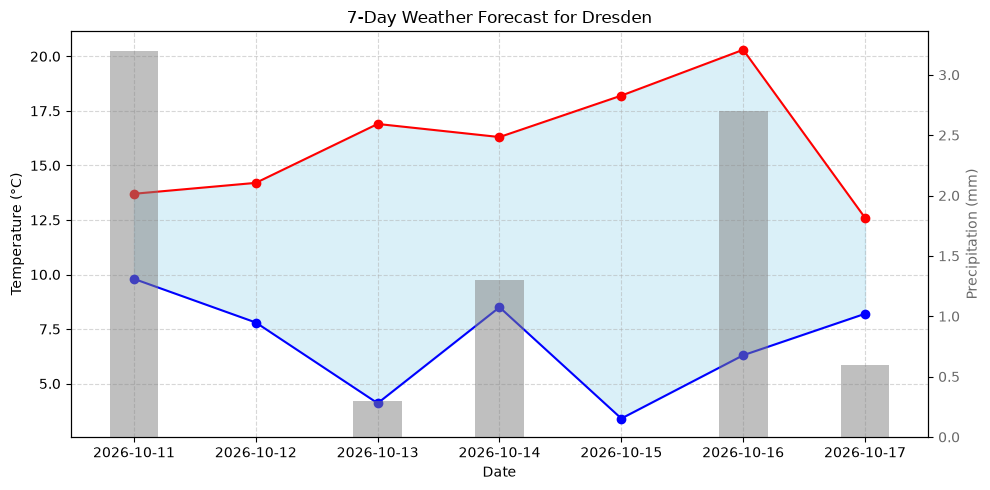

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from src.weather_client import geocode, get_forecast, parse_forecast_to_dataframe

# 1. Geocode location
candidates = geocode(LOCATION_NAME, CONTACT_EMAIL)

if not candidates:
    raise ValueError(f"No location found for '{LOCATION_NAME}'. Please check your configuration.")

# Handle ambiguity / pick the first best match
selected_location = candidates[0]
lat = selected_location["latitude"]
lon = selected_location["longitude"]
print(f"Selected Location: {selected_location['name']}, {selected_location.get('country', '')} (Lat: {lat}, Lon: {lon})")

# 2. Fetch forecast
forecast_json = get_forecast(lat, lon, days=7, contact_email=CONTACT_EMAIL)

# 3. Parse into DataFrame
df_forecast = parse_forecast_to_dataframe(forecast_json)

# 4. Display Formatted Table
print("\n--- 7-Day Weather Forecast Table ---")
display(df_forecast) # In Jupyter, display() renders a nice HTML table

# 5. Plotting Temperature Range and Precipitation
fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot temperature range
ax1.plot(df_forecast["Date"], df_forecast["Max Temp (°C)"], color="red", marker="o", label="Max Temp (°C)")
ax1.plot(df_forecast["Date"], df_forecast["Min Temp (°C)"], color="blue", marker="o", label="Min Temp (°C)")
ax1.fill_between(df_forecast["Date"], df_forecast["Min Temp (°C)"], df_forecast["Max Temp (°C)"], color="skyblue", alpha=0.3, label="Temp Range")
ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)", color="black")
ax1.tick_params(axis="y", labelcolor="black")
ax1.grid(True, linestyle="--", alpha=0.5)

# Plot precipitation on secondary axis
ax2 = ax1.twinx()
ax2.bar(df_forecast["Date"], df_forecast["Precipitation (mm)"], color="gray", alpha=0.5, width=0.4, label="Precipitation (mm)")
ax2.set_ylabel("Precipitation (mm)", color="dimgray")
ax2.tick_params(axis="y", labelcolor="dimgray")

plt.title(f"7-Day Weather Forecast for {selected_location['name']}")
fig.tight_layout()
plt.show()

## Part C: Robustness and Second Source Verification
Here we test our robust HTTP wrapper by passing deliberately broken inputs: an invalid coordinate/timeout and simulated connection errors.

In [4]:
from src.weather_client import robust_get, APIRequestError

print("Testing robustness with broken inputs...")

# Test 1: Tiny timeout (should trigger timeout / retry or custom exception)
try:
    print("\n[Test 1] Attempting request with extremely small timeout (0.001s)...")
    robust_get("https://api.open-meteo.com/v1/forecast", params={"latitude": 0, "longitude": 0}, timeout=0.001, max_retries=1)
except APIRequestError as e:
    print(f"Successfully caught expected error: {e}")

# Test 2: Invalid domain/network failure simulation
try:
    print("\n[Test 2] Attempting request to invalid URL...")
    robust_get("https://invalid-weather-api-domain-xyz123.com", timeout=2.0, max_retries=1)
except APIRequestError as e:
    print(f"Successfully caught expected error: {e}")

Testing robustness with broken inputs...

[Test 1] Attempting request with extremely small timeout (0.001s)...
Successfully caught expected error: Network error after 1 attempts: HTTPSConnectionPool(host='api.open-meteo.com', port=443): Max retries exceeded with url: /v1/forecast?latitude=0&longitude=0 (Caused by ConnectTimeoutError(<HTTPSConnection(host='api.open-meteo.com', port=443) at 0x1d4a98eb110>, 'Connection to api.open-meteo.com timed out. (connect timeout=0.001)'))

[Test 2] Attempting request to invalid URL...
Successfully caught expected error: Network error after 1 attempts: HTTPSConnectionPool(host='invalid-weather-api-domain-xyz123.com', port=443): Max retries exceeded with url: / (Caused by NameResolutionError("HTTPSConnection(host='invalid-weather-api-domain-xyz123.com', port=443): Failed to resolve 'invalid-weather-api-domain-xyz123.com' ([Errno 11001] getaddrinfo failed)"))


## Part D: Comprehensive Project Report

### 1. Data Flow Diagram
The data pipeline flows through three main phases:
[User Input: Location Name & Email] 
       │
       ▼
[Open-Meteo Geocoding API] ──(Resolves)──► [Latitude & Longitude Coordinates]
                                                  │
                                                  ▼
[Pandas DataFrame Conversion & Weather Code Mapping] ◄── [Open-Meteo Forecast API]
       │
       ▼
[Formatted HTML Table & Matplotlib Visualizations]

### 2. API Licensing and Usage Terms
- **Open-Meteo APIs:** Open-Meteo provides free weather data for non-commercial use without requiring an API key, relying instead on a polite `User-Agent` header for identification and rate limiting. For production or high-volume commercial applications, a commercial license or paid tier is available to guarantee uptime and dedicated infrastructure.
- **MET Norway Locationforecast 2.0:** Requires clear identification via a unique `User-Agent` (such as a project name and contact email) to comply with their terms of service and allow administrators to reach out if traffic spikes anomalously.

### 3. Reliability Issues and Error Handling
Real-world network communication is inherently volatile. To prevent application crashes, our client module implements:
- **Timeouts:** Preventing hanging requests by failing fast after a specified duration.
- **Exponential Backoff:** Retrying failed requests due to network glitches or server-side 5xx errors with increasing delays ($1.5^attempt$).
- **Custom Exceptions (`APIRequestError`):** Encapsulating low-level requests exceptions into clear, domain-specific errors.

### 4. Privacy Implications
Sending location queries (city names or coordinates) to third-party web APIs reveals user intent and geographic interest to service providers. While Open-Meteo does not require user accounts or tracking cookies for basic queries, IP addresses and search queries are logged temporarily on server infrastructure for security and rate-limiting purposes. For privacy-sensitive applications, location obfuscation or local caching strategies should be considered.